In [11]:
# Week 2: Supervised Machine Learning
# YuvaIntern AI Pioneers Internship

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
# Load California Housing dataset

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df_reg = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df_reg.shape)

print("\nFirst 5 rows:")
display(df_reg.head())

print("\nDataset information:")
df_reg.info()

print("\nMissing values per column:")
print(df_reg.isnull().sum())

print("\nStatistical summary:")
display(df_reg.describe().round(2))

Dataset loaded successfully!
Dataset shape: (20640, 9)

First 5 rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [13]:
# Separate features and target
X_reg = df_reg.drop(columns=["MedHouseVal"])
y_reg = df_reg["MedHouseVal"]

# Split into training and testing sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train_reg))
print("Testing samples:", len(X_test_reg))

# Define regression models
reg_models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

# Train and evaluate
reg_results = []
reg_predictions = {}

for name, model in reg_models.items():
    model.fit(X_train_reg, y_train_reg)
    predictions = model.predict(X_test_reg)
    reg_predictions[name] = predictions

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "MSE": mean_squared_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions)),
        "R2 Score": r2_score(y_test_reg, predictions)
    })

reg_results_df = pd.DataFrame(reg_results).round(4)

print("\nRegression Model Comparison:")
display(reg_results_df.sort_values("RMSE"))

Training samples: 16512
Testing samples: 4128

Regression Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,0.3275,0.2554,0.5053,0.8051
1,Decision Tree,0.4547,0.4952,0.7037,0.6221
0,Linear Regression,0.5332,0.5559,0.7456,0.5758


In [14]:
# Load the Breast Cancer Wisconsin dataset

from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)

df_clf = cancer.frame

print("Dataset shape:", df_clf.shape)
print("\nFirst five rows:")
display(df_clf.head())

print("\nClass distribution:")
print(df_clf["target"].map(
    {0: "Malignant", 1: "Benign"}
).value_counts())

print("\nMissing values:")
print(df_clf.isnull().sum().sum())

Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Class distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Missing values:
0


In [15]:
# Prepare classification data

X_clf = df_clf.drop(columns=["target"])
y_clf = df_clf["target"]

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

print("Training samples:", len(X_train_clf))
print("Testing samples:", len(X_test_clf))

# Define classification models
clf_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

# Train and evaluate
clf_results = []
clf_predictions = {}

for name, model in clf_models.items():
    model.fit(X_train_clf, y_train_clf)
    predictions = model.predict(X_test_clf)
    clf_predictions[name] = predictions

    clf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_clf, predictions),
        "Precision": precision_score(y_test_clf, predictions),
        "Recall": recall_score(y_test_clf, predictions),
        "F1 Score": f1_score(y_test_clf, predictions)
    })

clf_results_df = pd.DataFrame(clf_results).round(4)

print("\nClassification Model Comparison:")
display(clf_results_df.sort_values("F1 Score", ascending=False))

Training samples: 455
Testing samples: 114

Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
2,Random Forest,0.9561,0.9589,0.9722,0.9655
3,KNN,0.9561,0.9589,0.9722,0.9655
1,Decision Tree,0.9123,0.9559,0.9028,0.9286


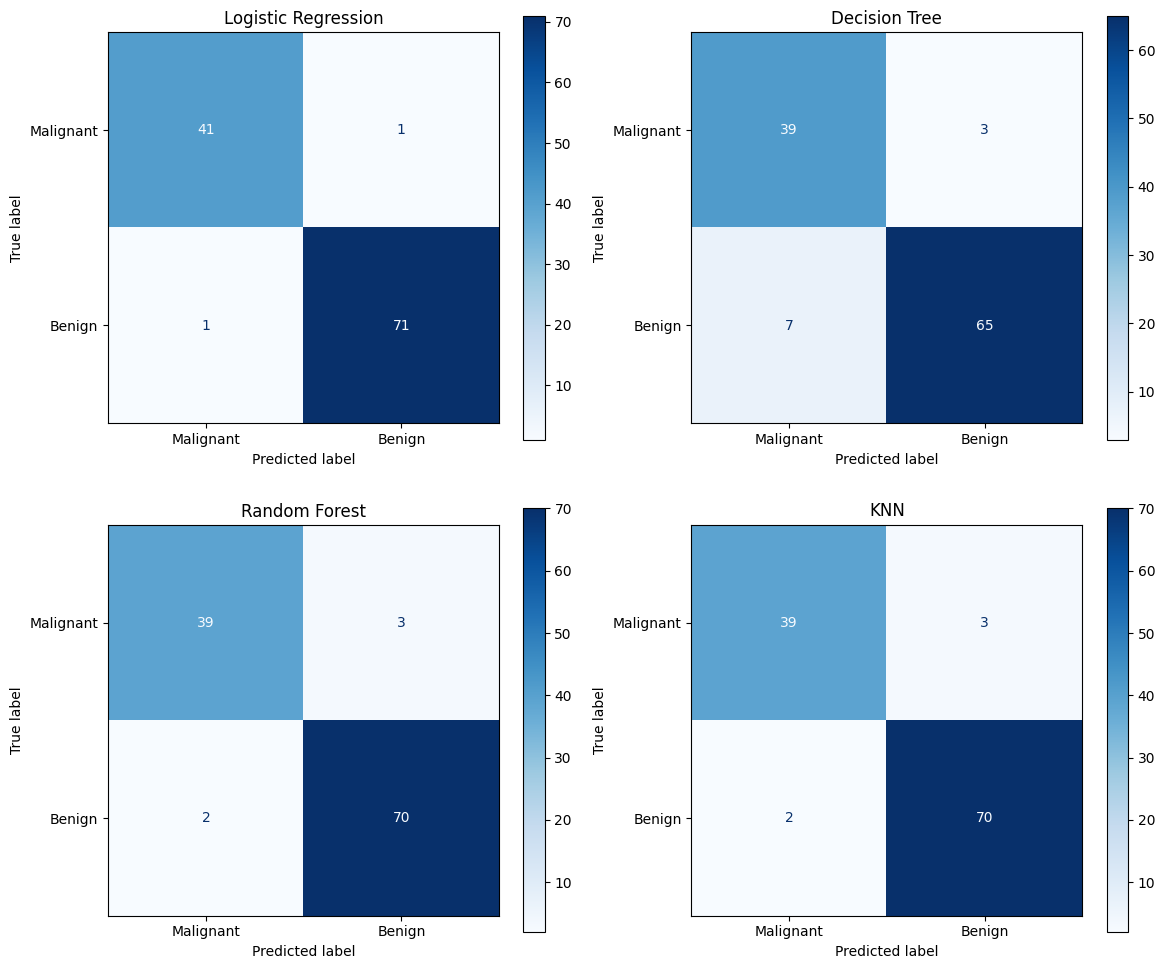

In [16]:
# Confusion matrices for all classification models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(
    axes.flatten(), clf_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test_clf,
        predictions,
        display_labels=["Malignant", "Benign"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

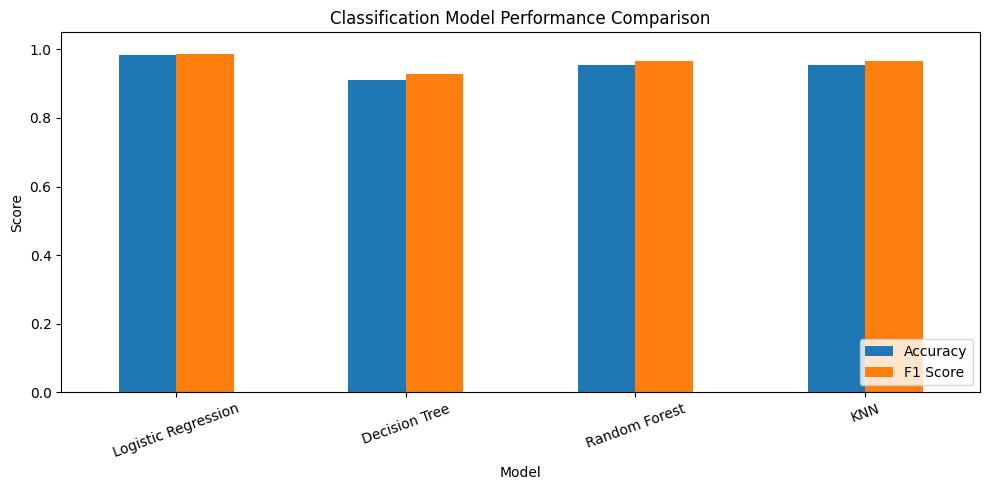

In [17]:
# Compare classification model accuracy and F1 score

comparison = clf_results_df.set_index("Model")[
    ["Accuracy", "F1 Score"]
]

comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
# Export evaluation tables

reg_results_df.to_csv(
    "regression_model_results.csv", index=False
)

clf_results_df.to_csv(
    "classification_model_results.csv", index=False
)

print("Both result tables exported successfully!")

Both result tables exported successfully!


In [19]:
from google.colab import files

files.download("regression_model_results.csv")
files.download("classification_model_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>